In [77]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def moving_average_filter(signal, window_size):
    """
    Apply a moving average filter to reduce noise in the signal.
    
    Parameters:
    - signal: The input noisy signal
    - window_size: The size of the moving window
    
    Returns:
    - filtered_signal: The smoothed signal
    """
    cumsum = np.cumsum(signal)
    cumsum[window_size:] = cumsum[window_size:] - cumsum[:-window_size]
    filtered_signal = cumsum[window_size - 1:] / window_size
    # Add the beginning part of the signal to match the original length
    filtered_signal = np.concatenate([signal[:window_size - 1], filtered_signal])
    return filtered_signal


In [78]:

# Generate a clean signal
np.random.seed(0)  # For reproducibility
time = np.linspace(0, 10, 1000)  # Time vector
clean_signal = np.sin(2 * np.pi * 1 * time)  # A simple sine wave signal


In [79]:

# Generate noisy signal
noise = np.random.normal(0, 0.5, size=time.shape)  # Gaussian noise
noisy_signal = clean_signal + noise  # Add noise to the clean signal


In [80]:

# Apply Moving Average Filter
window_size = 30  # Size of the moving window
smoothed_signal = moving_average_filter(noisy_signal, window_size)


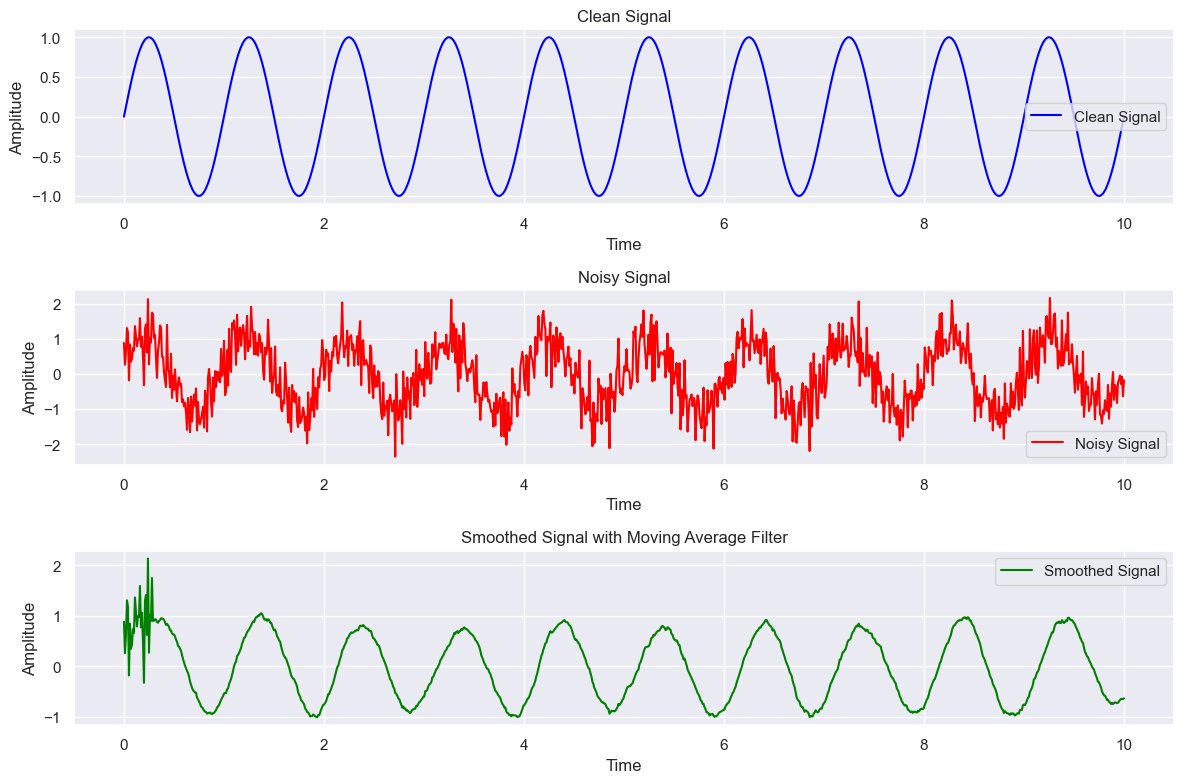

In [81]:

# Plot the signals
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(time, clean_signal, label='Clean Signal', color='blue')
plt.title('Clean Signal')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(time, noisy_signal, label='Noisy Signal', color='red')
plt.title('Noisy Signal')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(time, smoothed_signal, label='Smoothed Signal', color='green')
plt.title('Smoothed Signal with Moving Average Filter')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [82]:
# Function to normalize columns
def normalize_group(group):
    group[['x', 'y', 'z']] = (group[['x', 'y', 'z']] - group[['x', 'y', 'z']].mean()) / group[['x', 'y', 'z']].std()
    return group

wisdm = pd.read_csv('../code/datasets/WISDM_ar_v1.1_balanced.csv', header=None, sep=',', names=['user', 'activity', 'timestamp', 'x', 'y', 'z'])
wisdm = wisdm.groupby('user').apply(normalize_group)
wisdm = wisdm.reset_index(drop=True)
wisdm

C:\Users\tulio\AppData\Local\Temp\ipykernel_15852\4253220189.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wisdm = wisdm.groupby('user').apply(normalize_group)


,user,activity,timestamp,x,y,z
0,1,Walking,4992322339000,-0.091720,1.294345,-0.181997
1,1,Walking,4992422345000,0.390024,0.596599,-0.299797
2,1,Walking,4992722333000,1.040662,0.803481,0.175850
3,1,Walking,4993792341000,0.976051,0.650568,-0.224227
4,1,Walking,4993842298000,1.449861,0.680123,0.549256
...,...,...,...,...,...,...
290359,36,Standing,15049012250000,0.430103,0.422333,-0.155289
290360,36,Standing,15049062268000,0.330533,0.436234,-0.166769
290361,36,Standing,15049112287000,0.212525,0.439709,-0.155289
290362,36,Standing,15049162275000,0.002322,0.307651,-0.254785


In [83]:
walking_data = wisdm[(wisdm['activity'] == 'Walking') & (wisdm['user'] == 3)].copy()

standing_data = wisdm[(wisdm['activity'] == 'Standing') & (wisdm['user'] == 3)].copy()

sitting_data = wisdm[(wisdm['activity'] == 'Sitting') & (wisdm['user'] == 3)].copy()

jogging_data = wisdm[(wisdm['activity'] == 'Jogging') & (wisdm['user'] == 3)].copy()

In [84]:
def plot_four_time_series(data1, label1, data2, label2, data3, label3, data4, label4, title, min_y_limit=None, max_y_limit=None):
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="darkgrid")  # Set seaborn style
    plt.plot(data1, label=label1)
    plt.plot(data2, label=label2)
    plt.plot(data3, label=label3)
    plt.plot(data4, label=label4)
    plt.title(title)
    plt.xlabel('Sample')
    plt.ylabel('Value')
    plt.legend()
    if min_y_limit is not None and max_y_limit is not None:
        plt.ylim(min_y_limit, max_y_limit)  # Set y-axis limits
    plt.grid(True)
    plt.show()

In [85]:
axis = 'y'
maf_axis = 'y_maf'
ema_axis = 'y_ema'
title_axis = 'Y-axis'

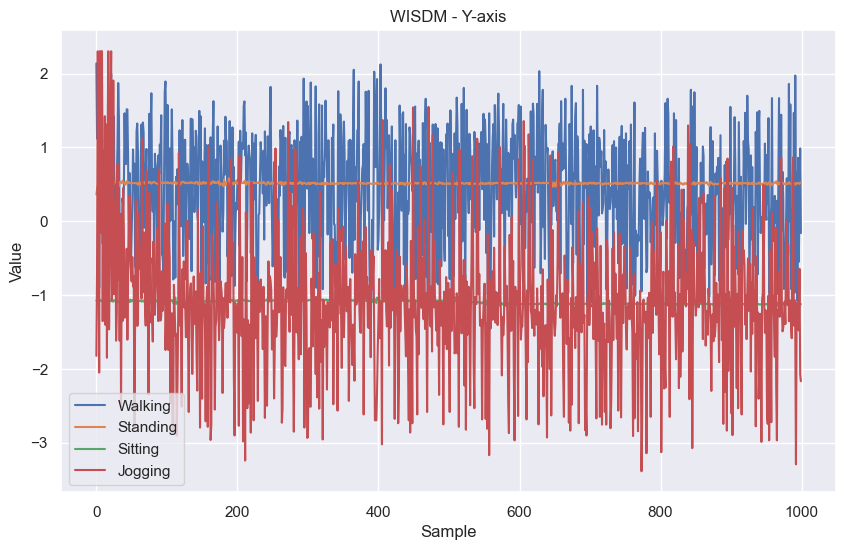

In [86]:
plot_four_time_series(walking_data[axis].iloc[0:1000].reset_index(drop=True), "Walking", 
                      standing_data[axis].iloc[0:1000].reset_index(drop=True), "Standing",
                      sitting_data[axis].iloc[0:1000].reset_index(drop=True), "Sitting", 
                      jogging_data[axis].iloc[0:1000].reset_index(drop=True), "Jogging",  
                      f'WISDM - {title_axis}')

In [87]:
# smooth_walking = moving_average_filter(walking_data[axis].iloc[0:1000].to_numpy(), 5)
# smooth_standing = moving_average_filter(standing_data[axis].iloc[0:1000].to_numpy(), 5)
# smooth_sitting = moving_average_filter(sitting_data[axis].iloc[0:1000].to_numpy(), 5)
# smooth_jogging = moving_average_filter(jogging_data[axis].iloc[0:1000].to_numpy(), 5)



walking_data[maf_axis] = walking_data[axis].rolling(window=20).mean()
standing_data[maf_axis] = standing_data[axis].rolling(window=20).mean()
sitting_data[maf_axis] = sitting_data[axis].rolling(window=20).mean()
jogging_data[maf_axis] = jogging_data[axis].rolling(window=20).mean()

walking_data[ema_axis] = walking_data[axis].ewm(span=30, adjust=False).mean()
standing_data[ema_axis] = standing_data[axis].ewm(span=30, adjust=False).mean()
sitting_data[ema_axis] = sitting_data[axis].ewm(span=30, adjust=False).mean()
jogging_data[ema_axis] = jogging_data[axis].ewm(span=30, adjust=False).mean()

smooth_walking = walking_data[maf_axis].iloc[0:1000].reset_index(drop=True).to_numpy()
smooth_standing = standing_data[maf_axis].iloc[0:1000].reset_index(drop=True).to_numpy()
smooth_sitting = sitting_data[maf_axis].iloc[0:1000].reset_index(drop=True).to_numpy()
smooth_jogging = jogging_data[maf_axis].iloc[0:1000].reset_index(drop=True).to_numpy()

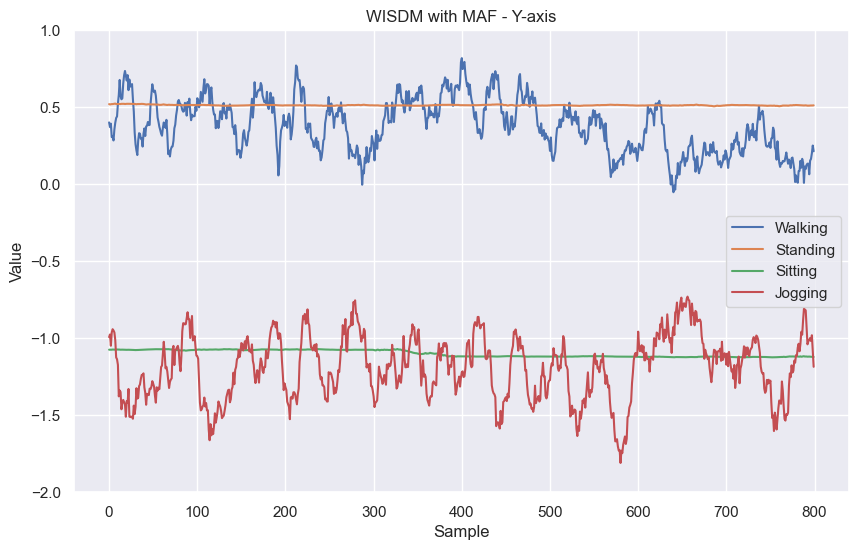

In [88]:
plot_four_time_series(
    smooth_walking[200:], "Walking", 
    smooth_standing[200:], "Standing", 
    smooth_sitting[200:], "Sitting",
    smooth_jogging[200:], "Jogging",
    f'WISDM with MAF - {title_axis}',
    min_y_limit=-2,
    max_y_limit=1)

In [89]:
smooth_walking = walking_data[ema_axis].iloc[0:1000].reset_index(drop=True).to_numpy()
smooth_standing = standing_data[ema_axis].iloc[0:1000].reset_index(drop=True).to_numpy()
smooth_sitting = sitting_data[ema_axis].iloc[0:1000].reset_index(drop=True).to_numpy()
smooth_jogging = jogging_data[ema_axis].iloc[0:1000].reset_index(drop=True).to_numpy()

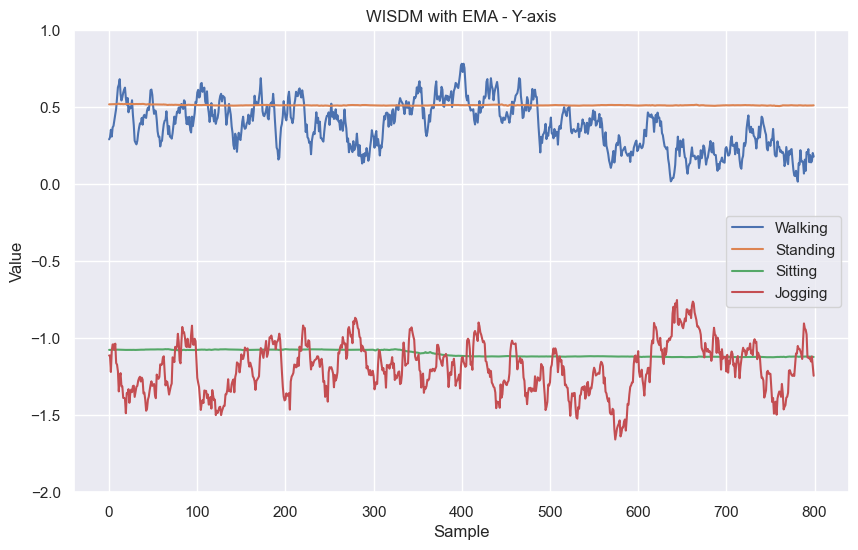

In [90]:
plot_four_time_series(
    smooth_walking[200:], "Walking", 
    smooth_standing[200:], "Standing", 
    smooth_sitting[200:], "Sitting",
    smooth_jogging[200:], "Jogging",
    f'WISDM with EMA - {title_axis}',
    min_y_limit=-2,
    max_y_limit=1)

# PAMAP2

In [91]:
# Function to normalize columns
def normalize_group(group):
    group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']] = (group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']] - group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']].mean()) / group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']].std()
    return group

pamap2 = pd.read_csv('../code/datasets/pamap_balanced.csv')
pamap2 = pamap2.groupby('subject_id').apply(normalize_group)
pamap2 = pamap2.reset_index(drop=True)
pamap2

C:\Users\tulio\AppData\Local\Temp\ipykernel_15852\238638118.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pamap2 = pamap2.groupby('subject_id').apply(normalize_group)


,timestamp,activity_id,hand_acc_16g_x,hand_acc_16g_y,hand_acc_16g_z,hand_acc_6g_x,hand_acc_6g_y,hand_acc_6g_z,hand_gyro_x,hand_gyro_y,hand_gyro_z,hand_mag_x,hand_mag_y,hand_mag_z,subject_id
0,309.53,2,1.173981,0.391292,0.007209,2.424750,9.12390,3.02166,0.037944,0.024816,-0.016013,15.0033,-67.00450,-1.055520,1
1,309.54,2,1.205812,0.395961,-0.151766,2.394240,9.13917,2.96125,0.040065,0.011347,0.009483,14.5708,-66.98840,-0.356026,1
2,309.55,2,1.189279,0.390786,-0.120353,2.378790,9.21468,2.84029,0.017566,-0.017100,-0.006770,14.6740,-67.31640,-0.707928,1
3,309.56,2,1.183728,0.374697,-0.104401,2.377660,9.13912,2.78006,-0.047912,0.007181,0.005693,14.7736,-67.42350,-1.288870,1
4,309.57,2,1.213794,0.391098,0.040929,2.361820,9.04862,2.78027,-0.046287,-0.000137,0.012163,15.1053,-66.56780,-1.630630,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926023,3630.07,5,1.268499,0.884639,2.541252,0.374732,2.89221,9.30422,-0.017195,0.006944,0.007758,17.7034,-4.55562,-41.179600,8
926024,3630.08,5,1.250323,0.870380,2.488375,0.526067,2.89119,9.37958,-0.032333,-0.044224,0.011758,17.9510,-4.56875,-41.048800,8
926025,3630.09,5,1.291976,0.870418,2.581465,0.630675,2.81489,9.34943,-0.004483,-0.001148,0.039415,17.9572,-4.94146,-41.177700,8
926026,3630.10,5,1.280116,0.875141,2.554826,0.720712,2.70858,9.40998,-0.022839,0.045628,0.049042,17.7079,-4.80414,-41.309300,8


In [92]:
pamap2[['x_maf', 'y_maf', 'z_maf']] = pamap2.groupby('subject_id')[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']].rolling(window=100).mean().reset_index(drop=True)
pamap2[['x_ema', 'y_ema', 'z_ema']] = pamap2.groupby('subject_id')[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']].ewm(span=150, adjust=False).mean().reset_index(drop=True)

In [93]:
axis = 'hand_acc_16g_y'

In [94]:
walking_data = pamap2[(pamap2['activity_id'] == 4) & (pamap2['subject_id'] == 5)].copy()

standing_data = pamap2[(pamap2['activity_id'] == 3) & (pamap2['subject_id'] == 5)].copy()

sitting_data = pamap2[(pamap2['activity_id'] == 2) & (pamap2['subject_id'] == 5)].copy()

jogging_data = pamap2[(pamap2['activity_id'] == 5) & (pamap2['subject_id'] == 5)].copy()

In [95]:
smooth_walking = walking_data[axis].iloc[0:5000].reset_index(drop=True).to_numpy()
smooth_standing = standing_data[axis].iloc[0:5000].reset_index(drop=True).to_numpy()
smooth_sitting = sitting_data[axis].iloc[0:5000].reset_index(drop=True).to_numpy()
smooth_jogging = jogging_data[axis].iloc[0:5000].reset_index(drop=True).to_numpy()

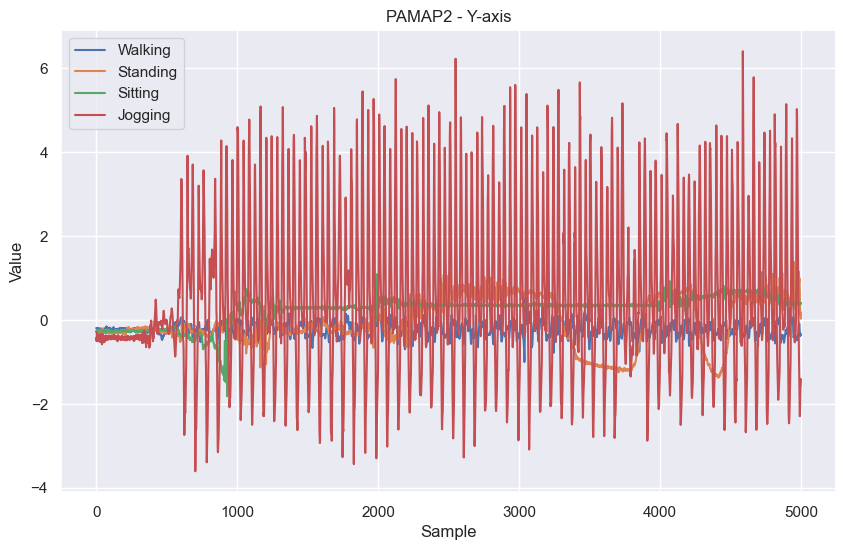

In [96]:
plot_four_time_series(
    smooth_walking, "Walking", 
    smooth_standing, "Standing", 
    smooth_sitting, "Sitting",
    smooth_jogging, "Jogging",
    f'PAMAP2 - {title_axis}')

In [97]:
smooth_walking = walking_data[maf_axis].iloc[0:5000].reset_index(drop=True).to_numpy()
smooth_standing = standing_data[maf_axis].iloc[0:5000].reset_index(drop=True).to_numpy()
smooth_sitting = sitting_data[maf_axis].iloc[0:5000].reset_index(drop=True).to_numpy()
smooth_jogging = jogging_data[maf_axis].iloc[0:5000].reset_index(drop=True).to_numpy()

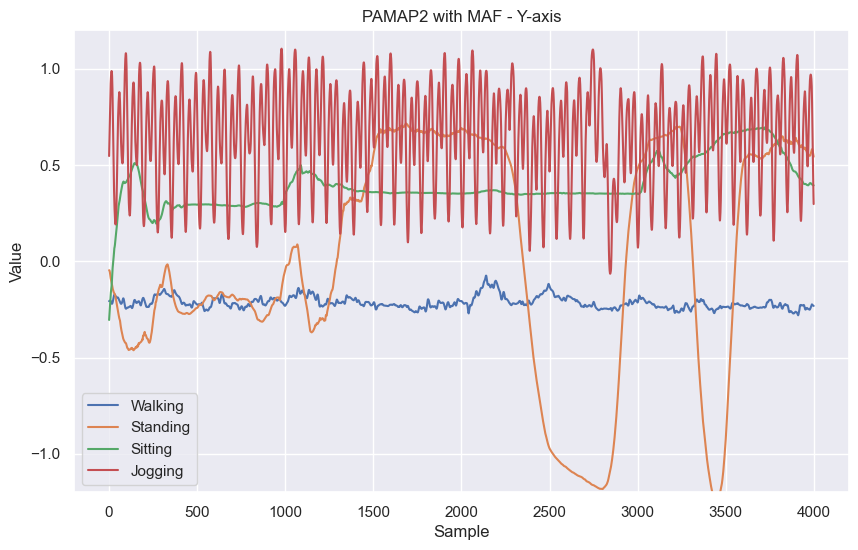

In [98]:
plot_four_time_series(
    smooth_walking[1000:], "Walking", 
    smooth_standing[1000:], "Standing", 
    smooth_sitting[1000:], "Sitting",
    smooth_jogging[1000:], "Jogging",
    f'PAMAP2 with MAF - {title_axis}',
    min_y_limit=-1.2,
    max_y_limit=1.2)

In [99]:
smooth_walking = walking_data[ema_axis].iloc[0:5000].reset_index(drop=True).to_numpy()
smooth_standing = standing_data[ema_axis].iloc[0:5000].reset_index(drop=True).to_numpy()
smooth_sitting = sitting_data[ema_axis].iloc[0:5000].reset_index(drop=True).to_numpy()
smooth_jogging = jogging_data[ema_axis].iloc[0:5000].reset_index(drop=True).to_numpy()

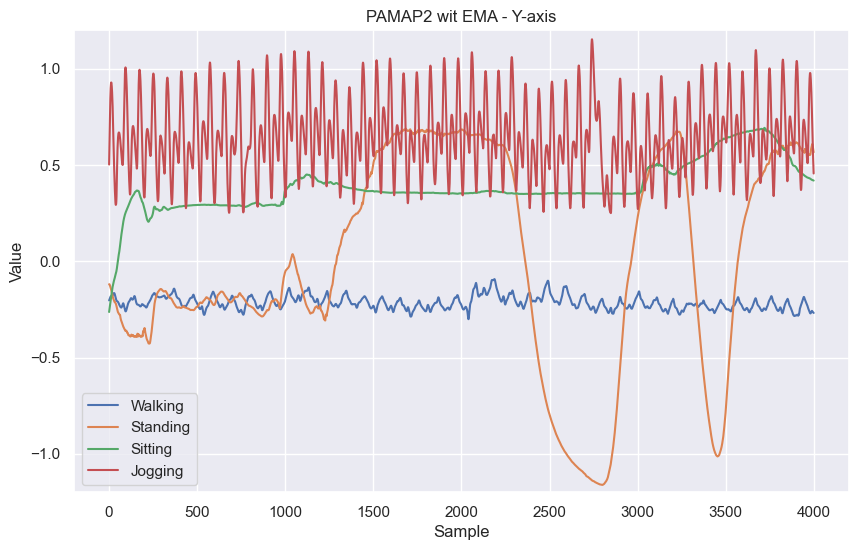

In [100]:
plot_four_time_series(
    smooth_walking[1000:], "Walking", 
    smooth_standing[1000:], "Standing", 
    smooth_sitting[1000:], "Sitting",
    smooth_jogging[1000:], "Jogging",
    f'PAMAP2 wit EMA - {title_axis}',
    min_y_limit=-1.2,
    max_y_limit=1.2)

# Opportunity

In [101]:
# Function to normalize columns
def normalize_group(group):
    group[['accX', 'accY', 'accZ']] = (group[['accX', 'accY', 'accZ']] - group[['accX', 'accY', 'accZ']].mean()) / group[['accX', 'accY', 'accZ']].std()
    return group

opportunity = pd.read_csv('../code/datasets/opportunity_preprocessed.csv')
opportunity = opportunity.dropna()
opportunity = opportunity.groupby('user_id').apply(normalize_group)
opportunity = opportunity.reset_index(drop=True)
opportunity

C:\Users\tulio\AppData\Local\Temp\ipykernel_15852\903125125.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  opportunity = opportunity.groupby('user_id').apply(normalize_group)


,timestamp,accX,accY,accZ,gyroX,gyroY,gyroZ,magneticX,magneticY,magneticZ,activity,user_id
0,0,-0.568511,0.505695,0.480930,-145.0,47.0,48.0,389.0,202.0,593.0,0,1
1,33,-0.611531,0.509278,0.447956,-318.0,-6.0,23.0,390.0,196.0,597.0,0,1
2,67,-0.584155,0.509278,0.388601,-426.0,13.0,49.0,392.0,192.0,598.0,0,1
3,100,-0.523537,0.437617,0.385304,-348.0,46.0,54.0,390.0,187.0,601.0,0,1
4,133,-0.484428,0.362373,0.421576,-329.0,76.0,100.0,389.0,179.0,605.0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
854319,1008123,-0.837009,0.444280,-0.103575,222.0,858.0,-67.0,145.0,721.0,-92.0,0,5
854320,1008157,-0.805397,0.645619,0.100670,467.0,710.0,-110.0,142.0,720.0,-101.0,0,5
854321,1008190,-0.708804,0.648919,0.193509,436.0,392.0,-185.0,139.0,721.0,-111.0,0,5
854322,1008223,-0.733391,0.738036,0.119238,145.0,149.0,-121.0,136.0,720.0,-120.0,0,5


In [102]:
opportunity[['x_maf', 'y_maf', 'z_maf']] = opportunity.groupby('user_id')[['accX', 'accY', 'accZ']].rolling(window=30).mean().reset_index(drop=True)
opportunity[['x_ema', 'y_ema', 'z_ema']] = opportunity.groupby('user_id')[['accX', 'accY', 'accZ']].ewm(span=45, adjust=False).mean().reset_index(drop=True)

In [103]:
axis = 'accY'

In [104]:
walking_data = opportunity[(opportunity['activity'] == 2) & (opportunity['user_id'] == 1)].copy()

standing_data = opportunity[(opportunity['activity'] == 1) & (opportunity['user_id'] == 1)].copy()

sitting_data = opportunity[(opportunity['activity'] == 4) & (opportunity['user_id'] == 1)].copy()

In [105]:
smooth_walking = walking_data[axis].iloc[0:2000].reset_index(drop=True).to_numpy()
smooth_standing = standing_data[axis].iloc[0:2000].reset_index(drop=True).to_numpy()
smooth_sitting = sitting_data[axis].iloc[0:2000].reset_index(drop=True).to_numpy()

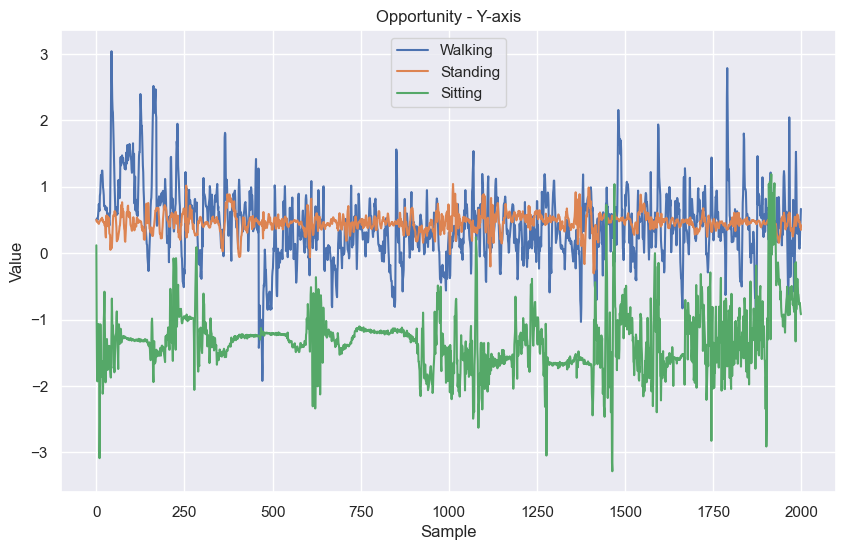

In [106]:
plot_four_time_series(
    smooth_walking, "Walking", 
    smooth_standing, "Standing", 
    smooth_sitting, "Sitting",
    [], "",	
    f'Opportunity - {title_axis}')

In [107]:
smooth_walking = walking_data[maf_axis].iloc[0:2000].reset_index(drop=True).to_numpy()
smooth_standing = standing_data[maf_axis].iloc[0:2000].reset_index(drop=True).to_numpy()
smooth_sitting = sitting_data[maf_axis].iloc[0:2000].reset_index(drop=True).to_numpy()

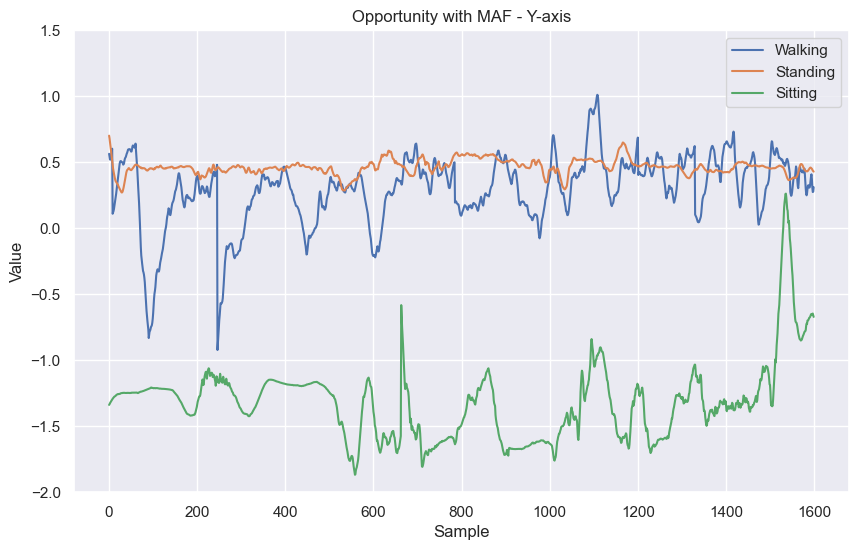

In [108]:
plot_four_time_series(
    smooth_walking[400:], "Walking", 
    smooth_standing[400:], "Standing", 
    smooth_sitting[400:], "Sitting",
    [], "",	
    f'Opportunity with MAF - {title_axis}',
    min_y_limit=-2,
    max_y_limit=1.5)

In [109]:
smooth_walking = walking_data[ema_axis].iloc[0:2000].reset_index(drop=True).to_numpy()
smooth_standing = standing_data[ema_axis].iloc[0:2000].reset_index(drop=True).to_numpy()
smooth_sitting = sitting_data[ema_axis].iloc[0:2000].reset_index(drop=True).to_numpy()

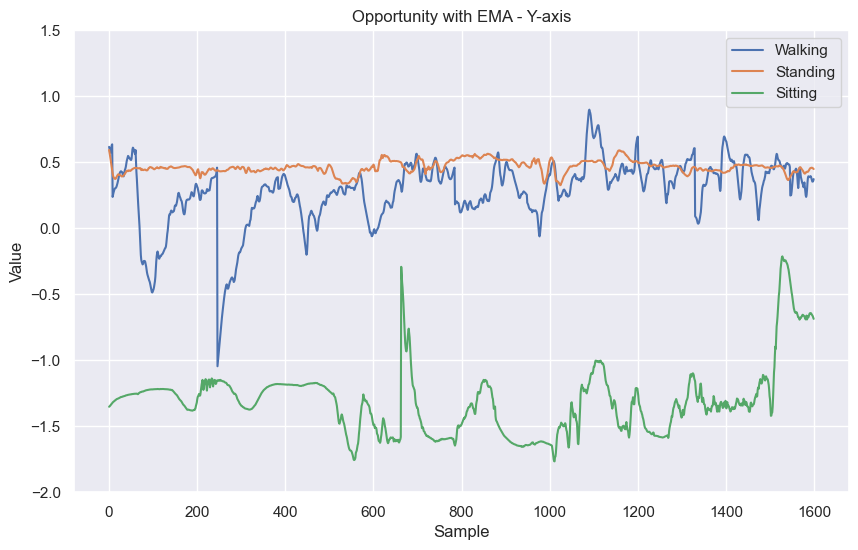

In [110]:
plot_four_time_series(
    smooth_walking[400:], "Walking", 
    smooth_standing[400:], "Standing", 
    smooth_sitting[400:], "Sitting",
    [], "",	
    f'Opportunity with EMA - {title_axis}',
    min_y_limit=-2,
    max_y_limit=1.5)